In [1]:
library(dplyr)
## visualization
library(ggplot2)
library(ggplot2)
library(gridExtra)
library(dplyr)
library(ggplot2)
library(cowplot)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘gridExtra’


The following object is masked from ‘package:dplyr’:

    combine




In [2]:
setwd("/home/liuxuan/metadata/10-10/PRJDB11578/")
initial_meta <- read.csv("SraRunTable.csv", header = TRUE)
head(initial_meta)
colnames(initial_meta)

,Run,Assay.Type,AvgSpotLen,Bases,BioProject,BioSample,BioSampleModel,Bytes,Center.Name,Collection_Date,⋯,LibrarySource,Organism,Platform,project_name,ReleaseDate,create_date,version,Sample.Name,Sample_name,SRA.Study
,<chr>,<chr>,<int>,<int>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,⋯,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>
1,DRR288244,AMPLICON,600,18483844,PRJDB11578,SAMD00317536,MIMS.me.human-oral,12400188,RIKEN_IMS,2013-07-25,⋯,METAGENOMIC,human oral metagenome,ILLUMINA,Oral microbiota of 37 Japanese adults,2022-09-12T00:00:00Z,2022-09-12T12:26:00Z,1,SAMD00317536,Wada-S02,DRP008973
2,DRR288245,AMPLICON,600,18037679,PRJDB11578,SAMD00317537,MIMS.me.human-oral,12134546,RIKEN_IMS,2013-07-25,⋯,METAGENOMIC,human oral metagenome,ILLUMINA,Oral microbiota of 37 Japanese adults,2022-09-12T00:00:00Z,2022-09-12T12:26:00Z,1,SAMD00317537,Wada-S03,DRP008973
3,DRR288246,AMPLICON,600,15824207,PRJDB11578,SAMD00317538,MIMS.me.human-oral,10607525,RIKEN_IMS,2013-07-31,⋯,METAGENOMIC,human oral metagenome,ILLUMINA,Oral microbiota of 37 Japanese adults,2022-09-12T00:00:00Z,2022-09-12T12:29:00Z,1,SAMD00317538,Wada-S04,DRP008973
4,DRR288247,AMPLICON,600,17332778,PRJDB11578,SAMD00317539,MIMS.me.human-oral,11477622,RIKEN_IMS,2013-07-31,⋯,METAGENOMIC,human oral metagenome,ILLUMINA,Oral microbiota of 37 Japanese adults,2022-09-12T00:00:00Z,2022-09-12T12:26:00Z,1,SAMD00317539,Wada-S05,DRP008973
5,DRR288248,AMPLICON,600,13781550,PRJDB11578,SAMD00317540,MIMS.me.human-oral,9361309,RIKEN_IMS,2013-08-22,⋯,METAGENOMIC,human oral metagenome,ILLUMINA,Oral microbiota of 37 Japanese adults,2022-09-12T00:00:00Z,2022-09-12T12:28:00Z,1,SAMD00317540,Wada-S07,DRP008973
6,DRR288249,AMPLICON,600,17399501,PRJDB11578,SAMD00317541,MIMS.me.human-oral,11633722,RIKEN_IMS,2013-08-22,⋯,METAGENOMIC,human oral metagenome,ILLUMINA,Oral microbiota of 37 Japanese adults,2022-09-12T00:00:00Z,2022-09-12T12:29:00Z,1,SAMD00317541,Wada-S08,DRP008973


[1] "Run"                            "Assay.Type"                    
 [3] "AvgSpotLen"                     "Bases"                         
 [5] "BioProject"                     "BioSample"                     
 [7] "BioSampleModel"                 "Bytes"                         
 [9] "Center.Name"                    "Collection_Date"               
[11] "Consent"                        "DATASTORE.filetype"            
[13] "DATASTORE.provider"             "DATASTORE.region"              
[15] "env_broad_scale"                "env_local_scale"               
[17] "env_medium"                     "Experiment"                    
[19] "geo_loc_name_country"           "geo_loc_name_country_continent"
[21] "geo_loc_name"                   "HOST"                          
[23] "Instrument"                     "lat_lon"                       
[25] "Library.Name"                   "LibraryLayout"                 
[27] "LibrarySelection"               "LibrarySource"                 
[29] "Organism"                       "Platform"                      
[31] "project_name"                   "ReleaseDate"                   
[33] "create_date"                    "version"                       
[35] "Sample.Name"                    "Sample_name"                   
[37] "SRA.Study"

In [3]:
uniform_meta <- data.frame(
    BioProject = initial_meta$BioProject,
    Run = initial_meta$Run,
    sample_name = initial_meta$'Sample_name',
    Age = NA,
    BMI = NA,
    Sex = NA,
    Region = 'V1-V2',
    Platform = initial_meta$Platform,
    Country = initial_meta$geo_loc_name_country,
    Site = initial_meta$env_medium,
    public_time = initial_meta$ReleaseDate,
    PCR_primers = 'F: AATGATACGGCGACCACCGAGATCTACACxxxxxxxxACACTCTTTCCCTACACGACGCTCTTCCGATCTagrgtttgatymtggctcag; R: CAAGCAGAAGACGGCATACGAGATxxxxxxxxGTGACTGGAGTTCAGACGTGTGCTCTTCCGATCTtgctgcctcccgtaggagt',
    title = "Increased levels of oral Streptococcus-derived D-alanine in patients with chronic kidney disease and diabetes mellitus",
    Disease_study = "YES",
    Status = NA,
    matched_samples = 'YES')

In [4]:
print(length(unique(uniform_meta$Run)))
print(length(unique(uniform_meta$sample_name)))

[1] 37
[1] 37


In [5]:
head(uniform_meta)

,BioProject,Run,sample_name,Age,BMI,Sex,Region,Platform,Country,Site,public_time,PCR_primers,title,Disease_study,Status,matched_samples
,<chr>,<chr>,<chr>,<lgl>,<lgl>,<lgl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<lgl>,<chr>
1,PRJDB11578,DRR288244,Wada-S02,NA,NA,NA,V1-V2,ILLUMINA,Japan,saliva,2022-09-12T00:00:00Z,F: AATGATACGGCGACCACCGAGATCTACACxxxxxxxxACACTCTTTCCCTACACGACGCTCTTCCGATCTagrgtttgatymtggctcag; R: CAAGCAGAAGACGGCATACGAGATxxxxxxxxGTGACTGGAGTTCAGACGTGTGCTCTTCCGATCTtgctgcctcccgtaggagt,Increased levels of oral Streptococcus-derived D-alanine in patients with chronic kidney disease and diabetes mellitus,YES,NA,YES
2,PRJDB11578,DRR288245,Wada-S03,NA,NA,NA,V1-V2,ILLUMINA,Japan,saliva,2022-09-12T00:00:00Z,F: AATGATACGGCGACCACCGAGATCTACACxxxxxxxxACACTCTTTCCCTACACGACGCTCTTCCGATCTagrgtttgatymtggctcag; R: CAAGCAGAAGACGGCATACGAGATxxxxxxxxGTGACTGGAGTTCAGACGTGTGCTCTTCCGATCTtgctgcctcccgtaggagt,Increased levels of oral Streptococcus-derived D-alanine in patients with chronic kidney disease and diabetes mellitus,YES,NA,YES
3,PRJDB11578,DRR288246,Wada-S04,NA,NA,NA,V1-V2,ILLUMINA,Japan,saliva,2022-09-12T00:00:00Z,F: AATGATACGGCGACCACCGAGATCTACACxxxxxxxxACACTCTTTCCCTACACGACGCTCTTCCGATCTagrgtttgatymtggctcag; R: CAAGCAGAAGACGGCATACGAGATxxxxxxxxGTGACTGGAGTTCAGACGTGTGCTCTTCCGATCTtgctgcctcccgtaggagt,Increased levels of oral Streptococcus-derived D-alanine in patients with chronic kidney disease and diabetes mellitus,YES,NA,YES
4,PRJDB11578,DRR288247,Wada-S05,NA,NA,NA,V1-V2,ILLUMINA,Japan,saliva,2022-09-12T00:00:00Z,F: AATGATACGGCGACCACCGAGATCTACACxxxxxxxxACACTCTTTCCCTACACGACGCTCTTCCGATCTagrgtttgatymtggctcag; R: CAAGCAGAAGACGGCATACGAGATxxxxxxxxGTGACTGGAGTTCAGACGTGTGCTCTTCCGATCTtgctgcctcccgtaggagt,Increased levels of oral Streptococcus-derived D-alanine in patients with chronic kidney disease and diabetes mellitus,YES,NA,YES
5,PRJDB11578,DRR288248,Wada-S07,NA,NA,NA,V1-V2,ILLUMINA,Japan,saliva,2022-09-12T00:00:00Z,F: AATGATACGGCGACCACCGAGATCTACACxxxxxxxxACACTCTTTCCCTACACGACGCTCTTCCGATCTagrgtttgatymtggctcag; R: CAAGCAGAAGACGGCATACGAGATxxxxxxxxGTGACTGGAGTTCAGACGTGTGCTCTTCCGATCTtgctgcctcccgtaggagt,Increased levels of oral Streptococcus-derived D-alanine in patients with chronic kidney disease and diabetes mellitus,YES,NA,YES
6,PRJDB11578,DRR288249,Wada-S08,NA,NA,NA,V1-V2,ILLUMINA,Japan,saliva,2022-09-12T00:00:00Z,F: AATGATACGGCGACCACCGAGATCTACACxxxxxxxxACACTCTTTCCCTACACGACGCTCTTCCGATCTagrgtttgatymtggctcag; R: CAAGCAGAAGACGGCATACGAGATxxxxxxxxGTGACTGGAGTTCAGACGTGTGCTCTTCCGATCTtgctgcctcccgtaggagt,Increased levels of oral Streptococcus-derived D-alanine in patients with chronic kidney disease and diabetes mellitus,YES,NA,YES


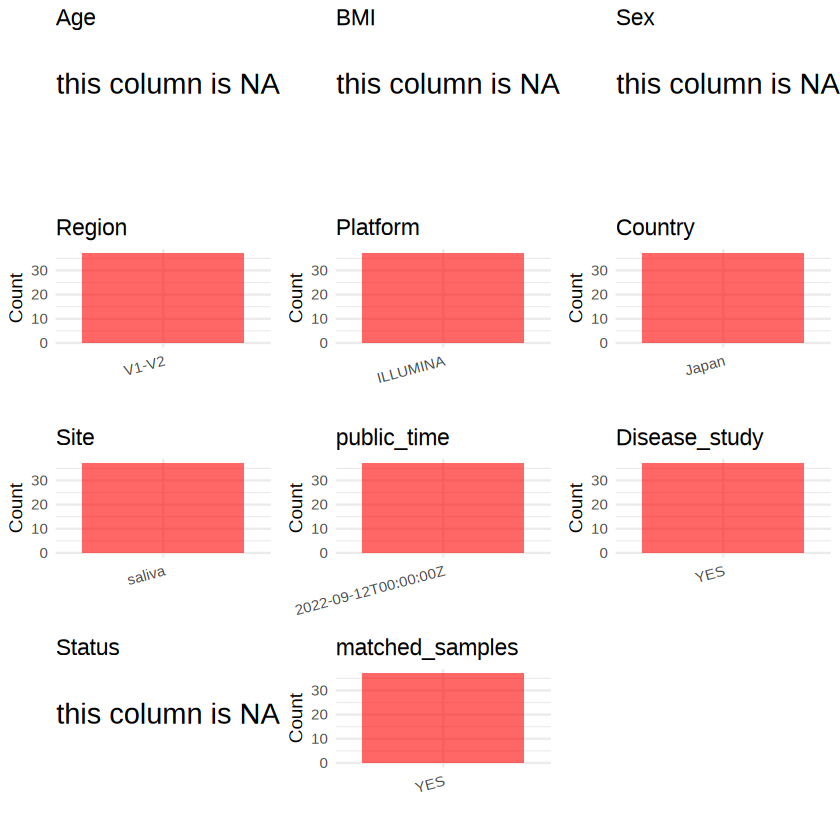

In [6]:
plot_data <- uniform_meta %>%
  select(-BioProject, -Run, -sample_name, -title)

create_simple_plots <- function(data) {
  plots <- list()
  
  for (col in colnames(data)) {
    if (all(is.na(data[[col]]))) {
      p <- ggplot() +
        annotate("text", x = 0.5, y = 0.5, label = "this column is NA", size = 6) +
        labs(title = col) +
        theme_void()
    } else if (is.numeric(data[[col]])) {
      p <- ggplot(data, aes(x = .data[[col]])) +
        geom_histogram(fill = "blue", alpha = 0.6, bins = 20, na.rm = TRUE) +
        labs(title = col) +
        theme_minimal()
    } else {
      count_data <- as.data.frame(table(data[[col]], useNA = "ifany"))
      p <- ggplot(count_data, aes(x = reorder(Var1, -Freq), y = Freq)) +
        geom_col(fill = "red", alpha = 0.6) +
        labs(title = col, x = NULL, y = "Count") +
        theme_minimal() +
        theme(axis.text.x = element_text(angle = 15, hjust = 1))
    }
    plots[[col]] <- p
  }
  return(plots)
}

plots <- create_simple_plots(plot_data)
p<-plot_grid(plots$Age, 
          plots$BMI, 
          plots$Sex, 
          plots$Region, 
          plots$Platform, 
          plots$Country, 
          plots$Site,
          plots$public_time, 
          #plots$PCR_primers,
          plots$Disease_study,
          plots$Status,
          plots$matched_samples,# add 
          ncol = 3, align = "hv", axis = "lb")
p

In [7]:
uniform_meta <- uniform_meta[, c("BioProject", "Run", "sample_name", "Age", "BMI", "Sex", "Region", "Platform", "Country", "Site", "public_time", "PCR_primers", "title", "Disease_study", "Status")]
write.csv(uniform_meta, file = "/home/liuxuan/metadata/10-10/PRJDB11578/metadata.csv", quote = T)